# Esercizi · La regressione lineare

*Metodi Matematici e Statistici per le Decisioni Economiche · A.A. 2026/27 · Esercitazione 1*


Un negozio online vuole capire da cosa dipende quanto spende un cliente in un anno. `clienti.csv` descrive 200 clienti: `spesa_annua` (euro spesi nell'anno), `ordini` (ordini nell'anno), `eta` (anni), `canale` (con cosa compra di solito: `Sito`, `App` o `Negozio`). Per vedere tutti i dettagli del dataset e capire le sue varibaili, consulta sempre il sito: https://www.vincnardelli.com/msd/dataset/clienti/

### 1.1 Importa polars, plotnine e statsmodels e leggi `clienti.csv` dal sito in una tabella `clienti`. Quanti clienti ci sono?

In [ ]:
import polars as pl
from plotnine import *
import statsmodels.formula.api as smf

In [ ]:
clienti = pl.read_csv("https://www.vincnardelli.com/msd/dati/clienti.csv")

In [ ]:
clienti.shape

(200, 5)

### 1.2 Studiamo il dataset. Come è strutturato? Quanti clienti comprano da App? Quanti fanno più ordini di 10? Quanti spendono meno di 100?

In [ ]:
clienti.describe()

statistic,cliente,canale,spesa_annua,ordini,eta
str,str,str,f64,f64,f64
"""count""","""200""","""200""",200.0,200.0,200.0
"""null_count""","""0""","""0""",0.0,0.0,0.0
"""mean""",null,null,187.495,4.61,37.365
"""std""",null,null,197.003839,4.858593,11.114831
"""min""","""C001""","""App""",15.0,1.0,18.0
"""25%""",null,null,77.0,2.0,29.0
"""50%""",null,null,135.0,3.0,37.0
"""75%""",null,null,221.0,6.0,45.0
"""max""","""C200""","""Sito""",1335.0,40.0,67.0


In [ ]:
clienti.columns

['cliente', 'canale', 'spesa_annua', 'ordini', 'eta']

In [ ]:
clienti.filter(pl.col("canale") == "App")

cliente,canale,spesa_annua,ordini,eta
str,str,i64,i64,i64
"""C001""","""App""",136,2,26
"""C004""","""App""",43,1,18
"""C006""","""App""",19,1,32
"""C007""","""App""",79,2,42
"""C011""","""App""",48,2,29
…,…,…,…,…
"""C189""","""App""",86,3,27
"""C192""","""App""",240,6,43
"""C193""","""App""",539,16,28


In [ ]:
clienti.filter(pl.col("ordini") > 10)

cliente,canale,spesa_annua,ordini,eta
str,str,i64,i64,i64
"""C019""","""Negozio""",401,11,47
"""C023""","""Negozio""",351,11,47
"""C030""","""Sito""",437,11,38
"""C050""","""Negozio""",216,11,27
"""C062""","""Sito""",586,12,35
…,…,…,…,…
"""C140""","""Sito""",1291,23,45
"""C167""","""Sito""",1335,40,30
"""C193""","""App""",539,16,28


In [ ]:
clienti.filter(pl.col("spesa_annua") < 100)

cliente,canale,spesa_annua,ordini,eta
str,str,i64,i64,i64
"""C004""","""App""",43,1,18
"""C006""","""App""",19,1,32
"""C007""","""App""",79,2,42
"""C011""","""App""",48,2,29
"""C013""","""App""",80,1,25
…,…,…,…,…
"""C185""","""Sito""",96,6,45
"""C188""","""App""",70,3,30
"""C189""","""App""",86,3,27


### 1.4 Disegna il grafico a dispersione di `ordini` (x) e `spesa_annua` (y) e calcola la correlazione.

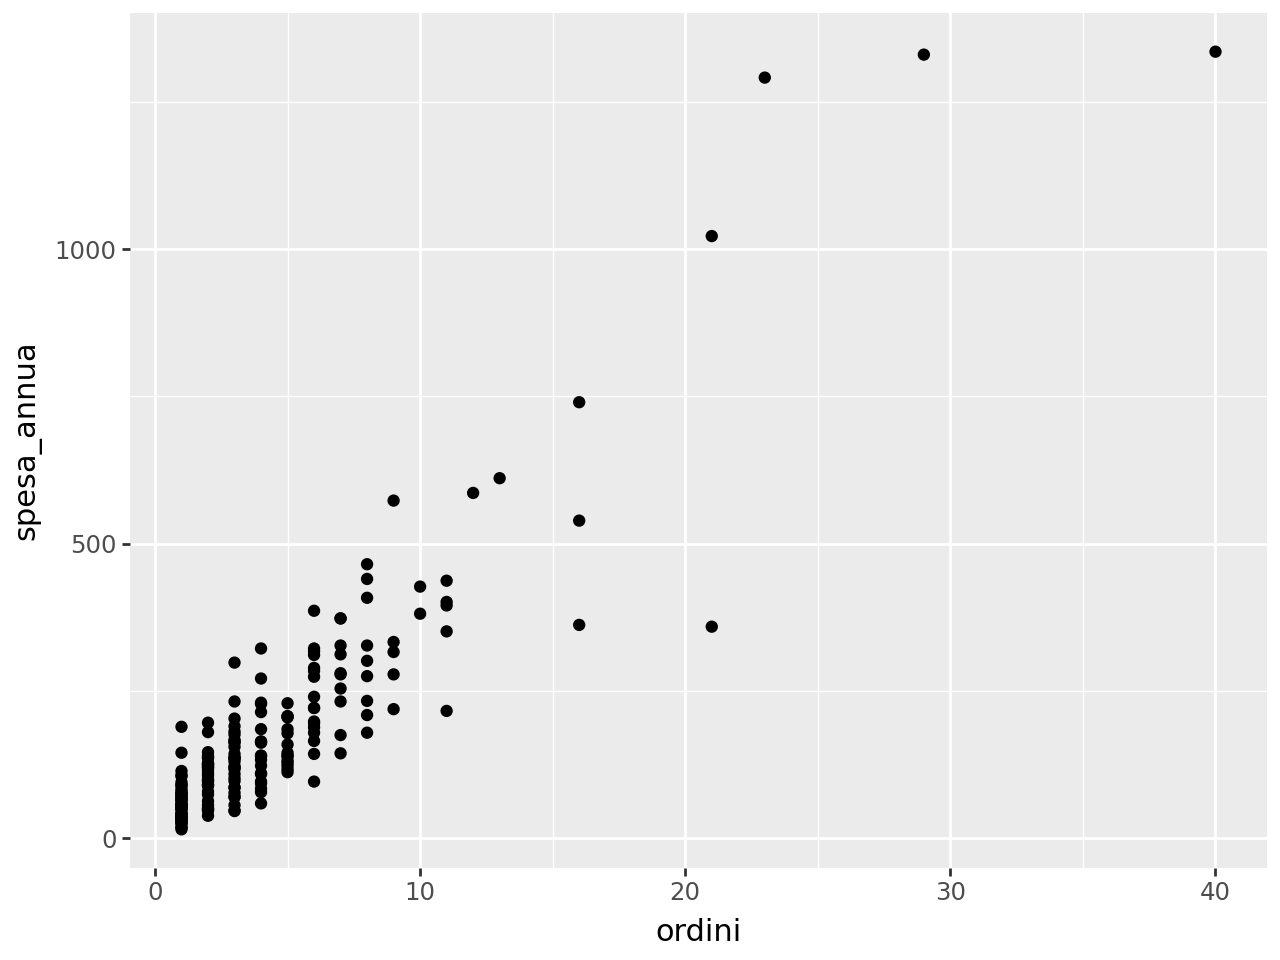

In [ ]:
ggplot(clienti, aes(x="ordini", y="spesa_annua")) + geom_point()
#al crescere del numero di ordini effettuati da un cliente, la sua spesa annua tende a crescere!

In [ ]:
# 0.91: positiva e molto forte. Al crescere del numero di ordini effettuati da un cliente, la sua spesa annua tende a crescere.
clienti.select(pl.corr("ordini", "spesa_annua"))

ordini
f64
0.911571


### 1.5 Stima il modello `spesa_annua ~ ordini` e guarda il `summary()`. Come leggi intercetta, pendenza, p-value e R²?

In [ ]:
# intercetta 17: la spesa prevista con 0 ordini
# pendenza 37: ogni ordine in più, circa 37 euro di spesa in più
# p-value 0.000: gli ordini contano; R² = 0.83: spiegano l'83% della variabilità della spesa
modello = smf.ols("spesa_annua ~ ordini", data=clienti).fit()
modello.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            spesa_annua   R-squared:                       0.831
Model:                            OLS   Adj. R-squared:                  0.830
Method:                 Least Squares   F-statistic:                     973.3
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           2.31e-78
Time:                        16:31:26   Log-Likelihood:                -1162.2
No. Observations:                 200   AIC:                             2328.
Df Residuals:                     198   BIC:                             2335.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     17.1005      7.925      2.158      0.032       1.473      32.728
ordini        36.9619      1.185     31.198      0.000      34.626      39.298
==============================================================================
Omnibus:                       40.818   Durbin-Watson:                   2.013
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              477.351
Skew:                           0.154   Prob(JB):                    2.21e-104
Kurtosis:                      10.562   Cond. No.                         9.33
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Per vedere i valori evidenziati singolarmente:

In [ ]:
modello.rsquared

np.float64(0.8309615813404674)

In [ ]:
modello.params

,0
Intercept,17.100516
ordini,36.961927


In [ ]:
modello.pvalues

,0
Intercept,3.213739e-02
ordini,2.308792e-78


### 1.6 Disegna la retta sopra i punti.

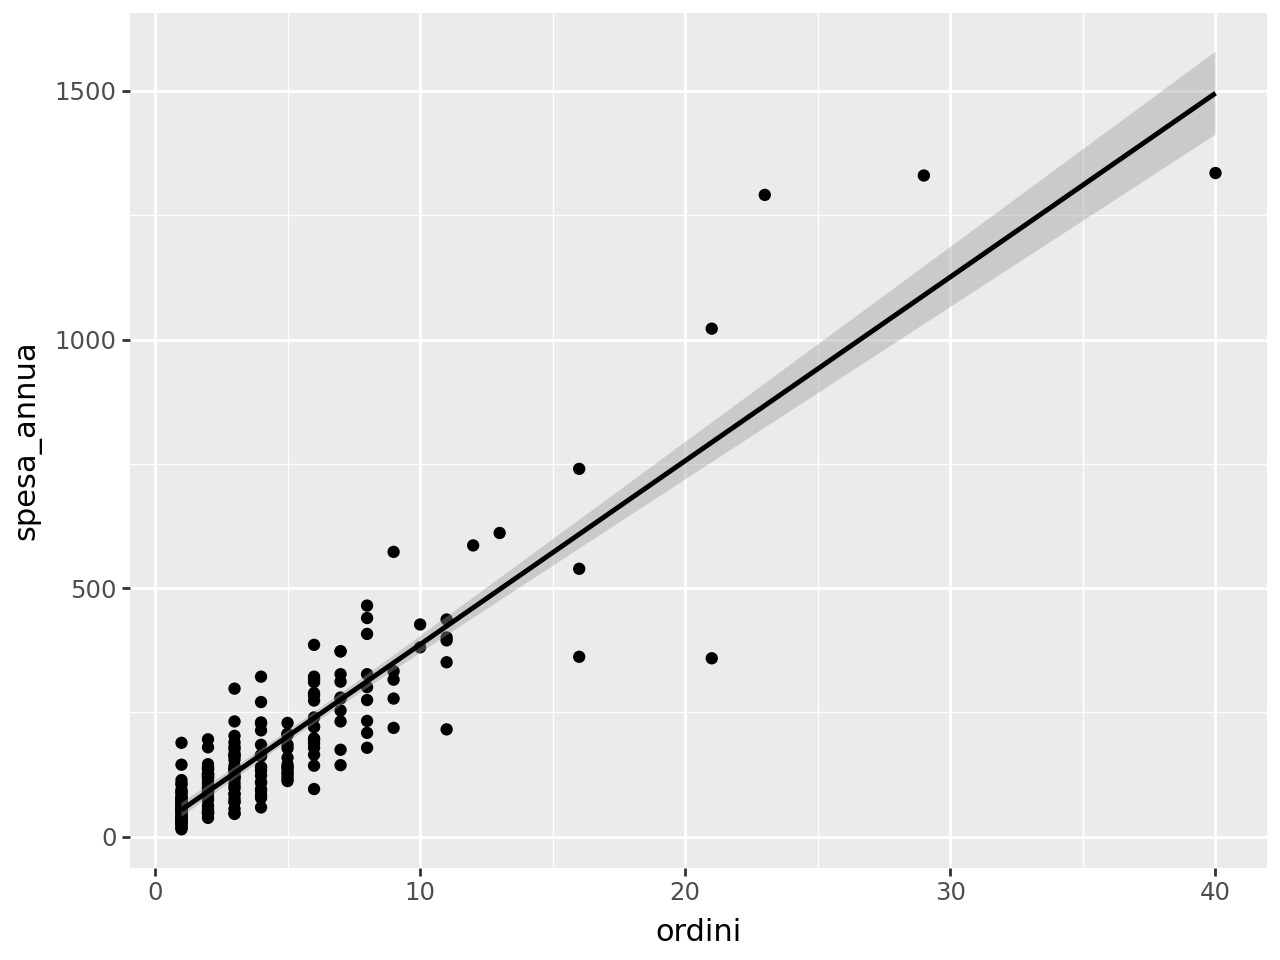

In [ ]:
ggplot(clienti, aes(x="ordini", y="spesa_annua")) + geom_point() + geom_smooth(method="lm")

### 1.8 L'età conta? Stima prima `spesa_annua ~ eta`, poi `spesa_annua ~ ordini + eta`.

In [ ]:
# da sola l'età sembra contare: p-value 0.01
modello_eta = smf.ols("spesa_annua ~ eta", data=clienti).fit()
modello_eta.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            spesa_annua   R-squared:                       0.033
Model:                            OLS   Adj. R-squared:                  0.028
Method:                 Least Squares   F-statistic:                     6.798
Date:                Wed, 11 Nov 2026   Prob (F-statistic):            0.00982
Time:                        16:31:29   Log-Likelihood:                -1336.6
No. Observations:                 200   AIC:                             2677.
Df Residuals:                     198   BIC:                             2684.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     66.8328     48.272      1.384      0.168     -28.361     162.026
eta            3.2293      1.239      2.607      0.010       0.787       5.672
==============================================================================
Omnibus:                      178.610   Durbin-Watson:                   2.102
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2558.292
Skew:                           3.504   Prob(JB):                         0.00
Kurtosis:                      19.058   Cond. No.                         137.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

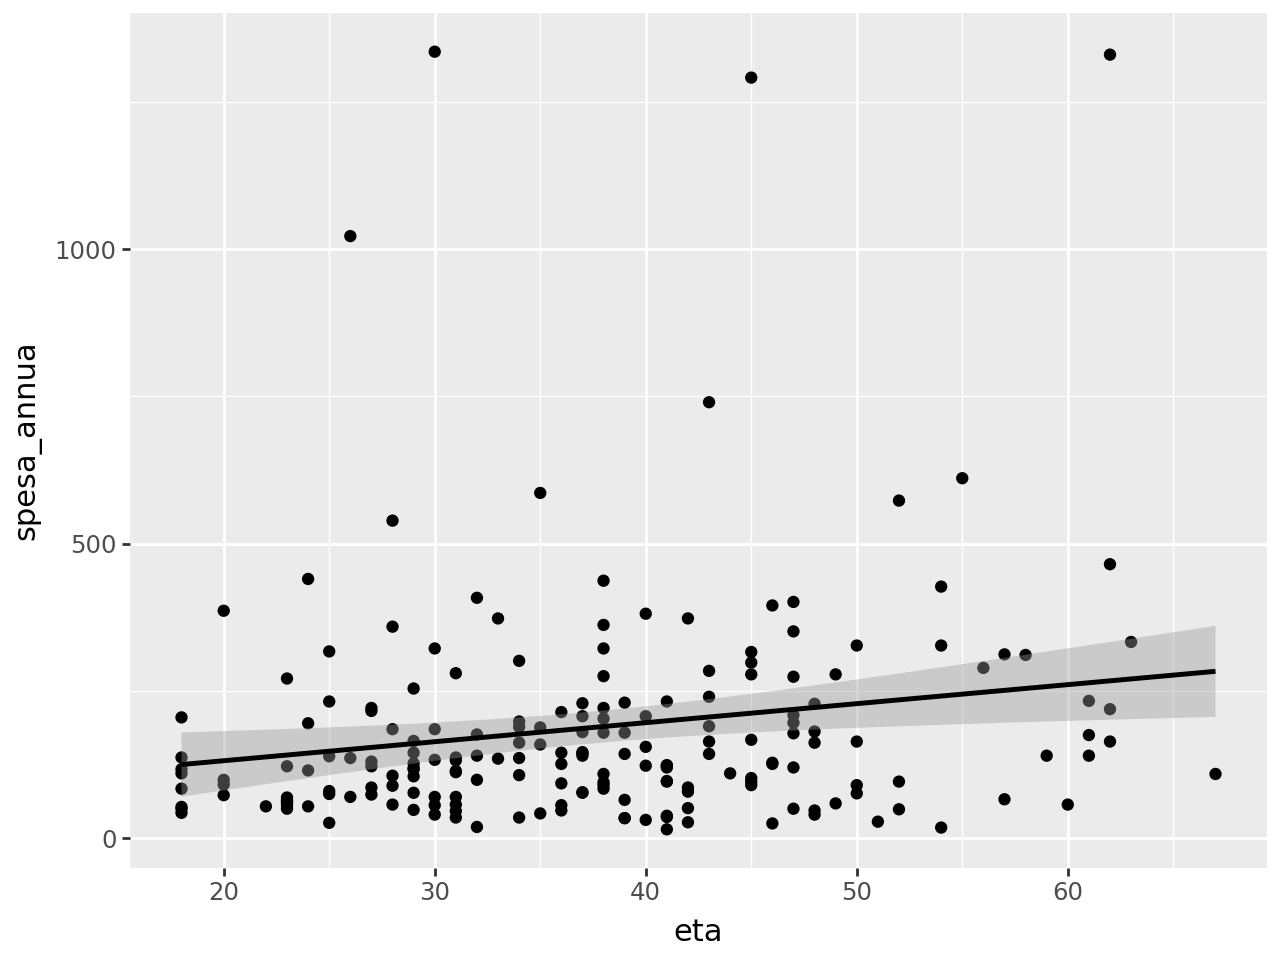

In [ ]:
ggplot(clienti, aes(x="eta", y="spesa_annua")) + geom_point() + geom_smooth(method="lm")

In [ ]:
# a parità di ordini no: p-value 0.30, sopra 0.05; R² resta 0.83
multiplo = smf.ols("spesa_annua ~ ordini + eta", data=clienti).fit()
multiplo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            spesa_annua   R-squared:                       0.832
Model:                            OLS   Adj. R-squared:                  0.830
Method:                 Least Squares   F-statistic:                     487.4
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           5.24e-77
Time:                        16:31:29   Log-Likelihood:                -1161.6
No. Observations:                 200   AIC:                             2329.
Df Residuals:                     197   BIC:                             2339.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.4701     20.306     -0.122      0.903     -42.516      37.576
ordini        36.7522      1.201     30.594      0.000      34.383      39.121
eta            0.5496      0.525      1.047      0.297      -0.486       1.585
==============================================================================
Omnibus:                       40.408   Durbin-Watson:                   2.006
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              443.488
Skew:                           0.199   Prob(JB):                     4.99e-97
Kurtosis:                      10.284   Cond. No.                         139.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""